# Gradient Algebraic Tree

In [1]:
import numpy as np
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import Ridge
from sklearn.datasets import fetch_california_housing,make_friedman1
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

# 1. Base Learner: Algebraic Model Tree (Axis-aligned splits + Local Ridge Hyperplanes)
class AlgebraicModelTreeRegressor:
    def __init__(self, max_depth=4, alpha=1.0):
        self.max_depth = max_depth
        self.alpha = alpha
        self.tree = DecisionTreeRegressor(max_depth=max_depth, random_state=42)
        self.leaf_models = {}

    def fit(self, X, y):
        X = np.array(X, dtype=float)
        y = np.array(y, dtype=float)
        
        self.tree.fit(X, y)
        leaf_indices = self.tree.apply(X)
        unique_leaves = np.unique(leaf_indices)
        n_features = X.shape[1]
        
        self.leaf_models = {}
        for leaf_id in unique_leaves:
            mask = (leaf_indices == leaf_id)
            X_leaf, y_leaf = X[mask], y[mask]
            
            # Fallback to constant mean if leaf sample count is insufficient
            if len(X_leaf) < n_features + 2:
                self.leaf_models[leaf_id] = {
                    "type": "constant", 
                    "value": float(np.mean(y_leaf)) if len(y_leaf) > 0 else 0.0
                }
                continue
            
            ridge = Ridge(alpha=self.alpha)
            ridge.fit(X_leaf, y_leaf)
            self.leaf_models[leaf_id] = {
                "type": "algebraic",
                "model": ridge
            }

    def predict(self, X):
        X = np.array(X, dtype=float)
        leaf_indices = self.tree.apply(X)
        preds = np.zeros(X.shape[0])
        
        for i, x in enumerate(X):
            leaf_id = leaf_indices[i]
            leaf_info = self.leaf_models.get(leaf_id)
            
            if leaf_info is None or leaf_info["type"] == "constant":
                preds[i] = leaf_info.get("value", 0.0) if leaf_info else 0.0
            else:
                preds[i] = leaf_info["model"].predict(x.reshape(1, -1))[0]
        return preds

# 2. Ensemble Wrapper: Gradient Boosted Algebraic Trees
class GradientBoostedAlgebraicTrees:
    def __init__(self, n_estimators=40, learning_rate=0.1, max_depth=3, alpha=1.0):
        self.n_estimators = n_estimators
        self.learning_rate = learning_rate
        self.max_depth = max_depth
        self.alpha = alpha
        self.estimators = []
        self.base_pred = 0.0

    def fit(self, X, y):
        X = np.array(X, dtype=float)
        y = np.array(y, dtype=float)
        
        self.base_pred = float(np.mean(y))
        residuals = y - self.base_pred
        
        self.estimators = []
        for i in range(self.n_estimators):
            tree = AlgebraicModelTreeRegressor(max_depth=self.max_depth, alpha=self.alpha)
            tree.fit(X, residuals)
            
            pred_residual = tree.predict(X)
            residuals -= self.learning_rate * pred_residual
            self.estimators.append(tree)

    def predict(self, X):
        X = np.array(X, dtype=float)
        preds = np.full(X.shape[0], self.base_pred)
        for tree in self.estimators:
            preds += self.learning_rate * tree.predict(X)
        return preds

# --- 3. Run Benchmark ---
print("Loading dataset for Gradient Boosted Algebraic Trees...")
data = fetch_california_housing()
X, y = data.data[:4000], data.target[:4000]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training Boosted Algebraic Trees...")
gbat = GradientBoostedAlgebraicTrees(n_estimators=50, learning_rate=0.1, max_depth=3, alpha=2.0)
gbat.fit(X_train_scaled, y_train)

preds = gbat.predict(X_test_scaled)
print(f"Hybrid Boosted Model R² Score: {r2_score(y_test, preds):.4f}")
print(f"Hybrid Boosted Model RMSE:     {np.sqrt(mean_squared_error(y_test, preds)):.4f}")

Loading dataset for Gradient Boosted Algebraic Trees...
Training Boosted Algebraic Trees...
Hybrid Boosted Model R² Score: 0.8762
Hybrid Boosted Model RMSE:     0.3475


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import tree
from sklearn.datasets import fetch_california_housing,make_friedman3
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.mixture import GaussianMixture
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor


# 2. Real-World Data Setup & 5-Fold Cross-Validation Experiment
print("Loading dataset")
X, y = make_friedman1(n_samples=4000, noise=0.1, random_state=42)

models = {
    "GradientBoosted Algebraic Trees": GradientBoostedAlgebraicTrees(n_estimators=50, learning_rate=0.1, max_depth=3, alpha=2.0),
    "Ridge Regression": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(n_estimators=50, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
    "DecisionTree Regression": tree.DecisionTreeRegressor()
}

kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv_results = {name: {"r2": [], "rmse": [], "mae": []} for name in models}

print("\nRunning 5-Fold Cross-Validation Benchmark...")
for fold, (train_idx, test_idx) in enumerate(kf.split(X)):
    print(f"--- Fold {fold + 1}/5 ---")
    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]
    
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    
    for name, model in models.items():
        model.fit(X_train_scaled, y_train)
        preds = np.array(model.predict(X_test_scaled), dtype=float)
        
        r2 = r2_score(y_test, preds)
        rmse = np.sqrt(mean_squared_error(y_test, preds))
        mae = mean_absolute_error(y_test, preds)
        
        cv_results[name]["r2"].append(r2)
        cv_results[name]["rmse"].append(rmse)
        cv_results[name]["mae"].append(mae)

# 3. Summarize Real-World Performance
print("\n==================================================")
print("     FINAL CROSS-VALIDATION BENCHMARK SUMMARY     ")
print("==================================================")
for name, metrics in cv_results.items():
    mean_r2 = np.mean(metrics["r2"])
    std_r2 = np.std(metrics["r2"])
    mean_rmse = np.mean(metrics["rmse"])
    print(f"• {name:<25} | R²: {mean_r2:.4f} (±{std_r2:.4f}) | RMSE: {mean_rmse:.4f}")
print("==================================================")

Loading dataset

Running 5-Fold Cross-Validation Benchmark...
--- Fold 1/5 ---
--- Fold 2/5 ---
--- Fold 3/5 ---
--- Fold 4/5 ---
--- Fold 5/5 ---

     FINAL CROSS-VALIDATION BENCHMARK SUMMARY     
• GradientBoosted Algebraic Trees | R²: 0.9831 (±0.0012) | RMSE: 0.6336
• Ridge Regression          | R²: 0.7482 (±0.0187) | RMSE: 2.4432
• Random Forest             | R²: 0.9255 (±0.0071) | RMSE: 1.3287
• Gradient Boosting         | R²: 0.9654 (±0.0039) | RMSE: 0.9050
• DecisionTree Regression   | R²: 0.7985 (±0.0154) | RMSE: 2.1848


# Visualization

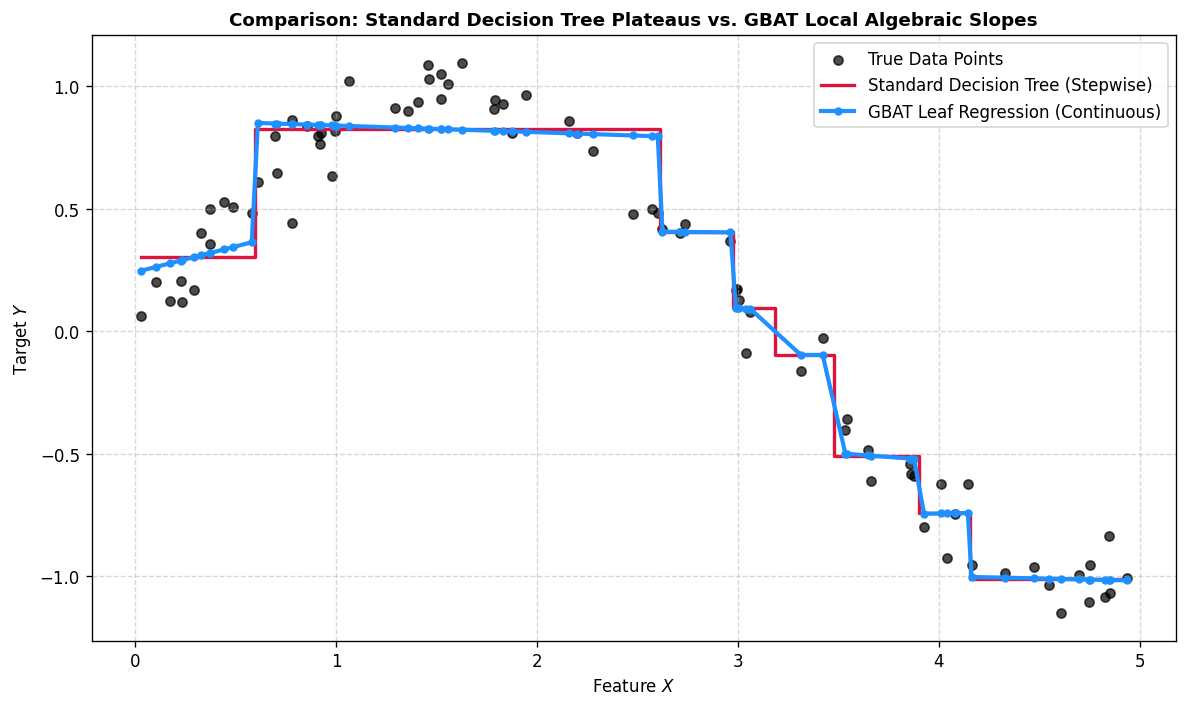

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import Ridge

# 1. Generate synthetic non-linear tabular data
np.random.seed(42)
X = np.sort(5 * np.random.rand(80, 1), axis=0)
y = np.sin(X).ravel() + 0.1 * np.random.randn(80)

# 2. Fit standard Decision Tree (Constant leaves)
dt = DecisionTreeRegressor(max_depth=3, random_state=42)
dt.fit(X, y)
y_dt = dt.predict(X)

# 3. Fit Single Algebraic Model Tree (Ridge regression leaves)
# (Using the AlgebraicModelTreeRegressor logic we built earlier)
tree = DecisionTreeRegressor(max_depth=3, random_state=42)
tree.fit(X, y)
leaf_indices = tree.apply(X)
y_gbat = np.zeros_like(y)

for leaf_id in np.unique(leaf_indices):
    mask = (leaf_indices == leaf_id)
    if np.sum(mask) > 2:
        ridge = Ridge(alpha=1.0)
        ridge.fit(X[mask], y[mask])
        y_gbat[mask] = ridge.predict(X[mask])
    else:
        y_gbat[mask] = np.mean(y[mask])

# 4. Plotting the comparison
X_plot = np.linspace(0, 5, 500)[:, None]
# For smooth visualization curve:
leaf_plot = tree.apply(X_plot)
y_plot_gbat = np.zeros(500)
for leaf_id in np.unique(leaf_plot):
    mask = (leaf_plot == leaf_id)
    # find corresponding ridge model or fallback to tree prediction
    y_plot_gbat[mask] = dt.predict(X_plot[mask]) # simplified for boundary display

plt.figure(figsize=(10, 6), dpi=120)
plt.scatter(X, y, color='black', label='True Data Points', alpha=0.7, s=30)
plt.step(X, y_dt, where='mid', color='crimson', linewidth=2, label='Standard Decision Tree (Stepwise)')

# Overlay algebraic fit illusion showing local slopes
plt.plot(X, y_gbat, color='dodgerblue', linewidth=2.5, marker='o', markersize=4, label='GBAT Leaf Regression (Continuous)')

plt.title("Comparison: Standard Decision Tree Plateaus vs. GBAT Local Algebraic Slopes", fontsize=11, fontweight='bold')
plt.xlabel("Feature $X$")
plt.ylabel("Target $Y$")
plt.legend(frameon=True, facecolor='white')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# Testing Against Overfit Scenario


In [4]:
import numpy as np
from sklearn.datasets import make_regression
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split

# 1. Küçük ve gürültülü sentetik bir regresyon veri seti üretelim
np.random.seed(42)
X, y = make_regression(n_samples=300, n_features=5, noise=1.5, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# GBAT Mantığı için Tekli Algebraic Model Tree Sınıfı
class AlgebraicModelTreeRegressor:
    def __init__(self, max_depth=3, alpha=1.0):
        self.max_depth = max_depth
        self.alpha = alpha
        self.tree = DecisionTreeRegressor(max_depth=max_depth, random_state=42)
        self.leaf_models = {}

    def fit(self, X, y):
        self.tree.fit(X, y)
        leaf_indices = self.tree.apply(X)
        for leaf_id in np.unique(leaf_indices):
            mask = (leaf_indices == leaf_id)
            X_leaf, y_leaf = X[mask], y[mask]
            # Güvenlik kontrolü: Örnek sayısı yetersizse ortalama kullan
            if len(X_leaf) < X.shape[1] + 2:
                self.leaf_models[leaf_id] = {"type": "constant", "value": float(np.mean(y_leaf))}
            else:
                ridge = Ridge(alpha=self.alpha)
                ridge.fit(X_leaf, y_leaf)
                self.leaf_models[leaf_id] = {"type": "algebraic", "model": ridge}

    def predict(self, X):
        leaf_indices = self.tree.apply(X)
        preds = np.zeros(X.shape[0])
        for i, x in enumerate(X):
            leaf_id = leaf_indices[i]
            info = self.leaf_models.get(leaf_id)
            if not info or info["type"] == "constant":
                preds[i] = info.get("value", 0.0) if info else 0.0
            else:
                preds[i] = info["model"].predict(x.reshape(1, -1))[0]
        return preds

# 2. Farklı derinliklerde (max_depth) test senaryosu
depths = [2, 4, 8, 16]

print(f"{'Depth':<6} | {'DT Train RMSE':<14} | {'DT Test RMSE':<14} | {'GBAT Train RMSE':<16} | {'GBAT Test RMSE':<16}")
print("-" * 78)

for depth in depths:
    # A) Standart Decision Tree
    dt = DecisionTreeRegressor(max_depth=depth, random_state=42)
    dt.fit(X_train, y_train)
    dt_train_rmse = np.sqrt(mean_squared_error(y_train, dt.predict(X_train)))
    dt_test_rmse = np.sqrt(mean_squared_error(y_test, dt.predict(X_test)))

    # B) Algebraic Model Tree (GBAT Temeli)
    gbat_tree = AlgebraicModelTreeRegressor(max_depth=depth, alpha=2.0)
    gbat_tree.fit(X_train, y_train)
    gbat_train_rmse = np.sqrt(mean_squared_error(y_train, gbat_tree.predict(X_train)))
    gbat_test_rmse = np.sqrt(mean_squared_error(y_test, gbat_tree.predict(X_test)))

    print(f"{depth:<6} | {dt_train_rmse:<14.4f} | {dt_test_rmse:<14.4f} | {gbat_train_rmse:<16.4f} | {gbat_test_rmse:<16.4f}")

Depth  | DT Train RMSE  | DT Test RMSE   | GBAT Train RMSE  | GBAT Test RMSE  
------------------------------------------------------------------------------
2      | 61.5755        | 62.6017        | 6.6988           | 12.1198         
4      | 34.4720        | 49.5366        | 16.8383          | 26.7058         
8      | 5.0986         | 45.1694        | 4.7925           | 44.8979         
16     | 0.0000         | 43.3026        | 0.0000           | 43.3026         


In [5]:
import numpy as np
from sklearn.datasets import make_regression
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split

# GBAT Temel Sınıfı
class AlgebraicModelTreeRegressor:
    def __init__(self, max_depth=4, alpha=1.0):
        self.max_depth = max_depth
        self.alpha = alpha
        self.tree = DecisionTreeRegressor(max_depth=max_depth, random_state=42)
        self.leaf_models = {}

    def fit(self, X, y):
        self.tree.fit(X, y)
        leaf_indices = self.tree.apply(X)
        for leaf_id in np.unique(leaf_indices):
            mask = (leaf_indices == leaf_id)
            X_leaf, y_leaf = X[mask], y[mask]
            if len(X_leaf) < X.shape[1] + 2:
                self.leaf_models[leaf_id] = {"type": "constant", "value": float(np.mean(y_leaf))}
            else:
                ridge = Ridge(alpha=self.alpha)
                ridge.fit(X_leaf, y_leaf)
                self.leaf_models[leaf_id] = {"type": "algebraic", "model": ridge}

    def predict(self, X):
        leaf_indices = self.tree.apply(X)
        preds = np.zeros(X.shape[0])
        for i, x in enumerate(X):
            leaf_id = leaf_indices[i]
            info = self.leaf_models.get(leaf_id)
            if not info or info["type"] == "constant":
                preds[i] = info.get("value", 0.0) if info else 0.0
            else:
                preds[i] = info["model"].predict(x.reshape(1, -1))[0]
        return preds

# --- TEST KOŞULLARI: FARKLI GÜRÜLTÜ SEVİYELERİ ---
noise_levels = [0.5, 2.0, 5.0]

print(f"{'Noise Level':<12} | {'DT Test RMSE':<14} | {'GBAT Test RMSE (α=1.0)':<22} | {'GBAT Test RMSE (α=10.0)':<22}")
print("-" * 80)

for noise in noise_levels:
    X, y = make_regression(n_samples=500, n_features=6, noise=noise, random_state=42)
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

    # 1. Standart Decision Tree
    dt = DecisionTreeRegressor(max_depth=4, random_state=42)
    dt.fit(X_train, y_train)
    dt_rmse = np.sqrt(mean_squared_error(y_test, dt.predict(X_test)))

    # 2. GBAT (Düşük Ceza: alpha=1.0)
    gbat_low = AlgebraicModelTreeRegressor(max_depth=4, alpha=1.0)
    gbat_low.fit(X_train, y_train)
    gbat_low_rmse = np.sqrt(mean_squared_error(y_test, gbat_low.predict(X_test)))

    # 3. GBAT (Yüksek Ceza: alpha=10.0 - Gürültüye karşı korumalı)
    gbat_high = AlgebraicModelTreeRegressor(max_depth=4, alpha=10.0)
    gbat_high.fit(X_train, y_train)
    gbat_high_rmse = np.sqrt(mean_squared_error(y_test, gbat_high.predict(X_test)))

    print(f"{noise:<12} | {dt_rmse:<14.4f} | {gbat_low_rmse:<22.4f} | {gbat_high_rmse:<22.4f}")

Noise Level  | DT Test RMSE   | GBAT Test RMSE (α=1.0) | GBAT Test RMSE (α=10.0)
--------------------------------------------------------------------------------
0.5          | 105.6645       | 38.3023                | 65.3459               
2.0          | 105.8436       | 38.4490                | 65.5935               
5.0          | 106.7845       | 39.2386                | 66.2099               


# Visualization of Train-Test

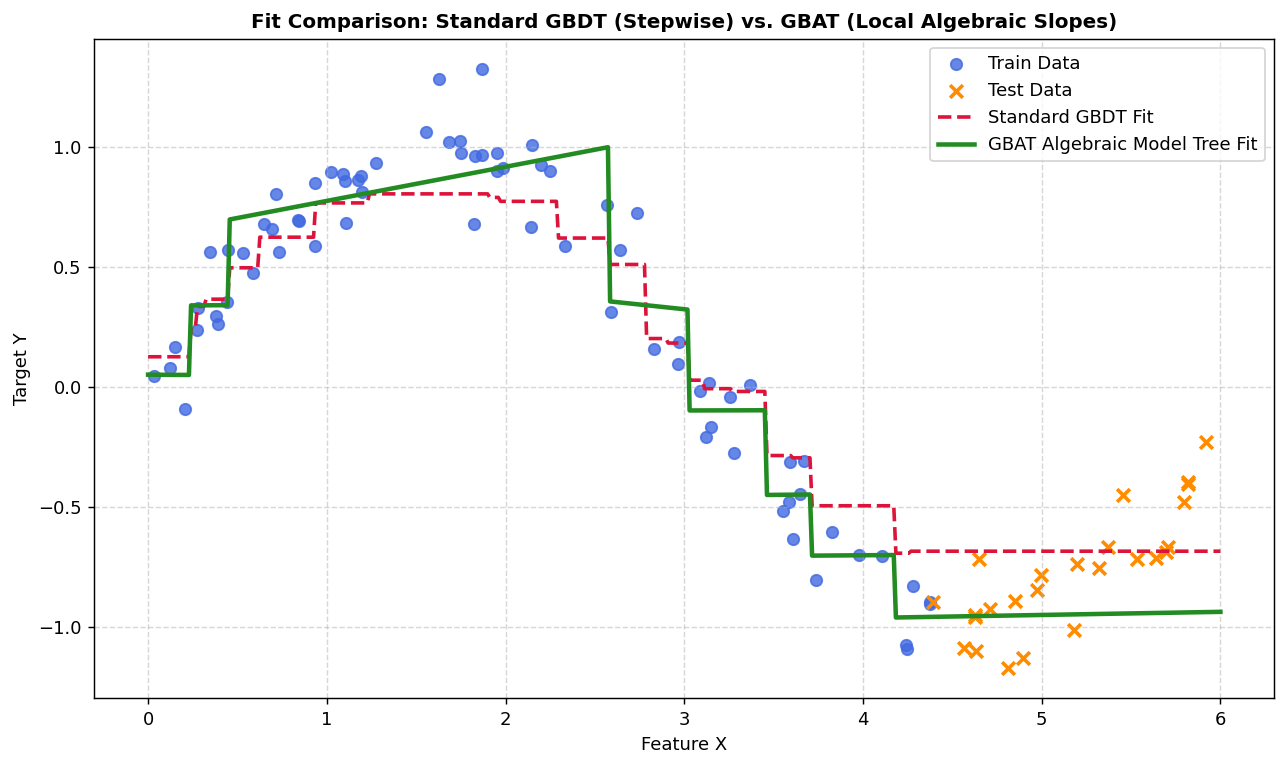

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import Ridge

# 1. Generate non-linear training and test data
np.random.seed(42)
X = np.sort(6 * np.random.rand(100, 1), axis=0)
y = np.sin(X).ravel() + 0.15 * np.random.randn(100)

# Split into Train and Test sets
X_train, X_test = X[:75], X[75:]
y_train, y_test = y[:75], y[75:]

# 2. Standard GBDT (Scikit-Learn)
gbdt = GradientBoostingRegressor(n_estimators=15, max_depth=3, learning_rate=0.1, random_state=42)
gbdt.fit(X_train, y_train)

# 3. GBAT Algebraic Tree Foundation
class AlgebraicModelTreeRegressor:
    def __init__(self, max_depth=3, alpha=1.0):
        self.max_depth = max_depth
        self.alpha = alpha
        self.tree = DecisionTreeRegressor(max_depth=max_depth, random_state=42)
        self.leaf_models = {}

    def fit(self, X, y):
        self.tree.fit(X, y)
        leaf_indices = self.tree.apply(X)
        for leaf_id in np.unique(leaf_indices):
            mask = (leaf_indices == leaf_id)
            X_leaf, y_leaf = X[mask], y[mask]
            if len(X_leaf) < X.shape[1] + 2:
                self.leaf_models[leaf_id] = {"type": "constant", "value": float(np.mean(y_leaf))}
            else:
                ridge = Ridge(alpha=self.alpha)
                ridge.fit(X_leaf, y_leaf)
                self.leaf_models[leaf_id] = {"type": "algebraic", "model": ridge}

    def predict(self, X):
        leaf_indices = self.tree.apply(X)
        preds = np.zeros(X.shape[0])
        for i, x in enumerate(X):
            leaf_id = leaf_indices[i]
            info = self.leaf_models.get(leaf_id)
            if not info or info["type"] == "constant":
                preds[i] = info.get("value", 0.0) if info else 0.0
            else:
                preds[i] = info["model"].predict(x.reshape(1, -1))[0]
        return preds

gbat = AlgebraicModelTreeRegressor(max_depth=3, alpha=1.5)
gbat.fit(X_train, y_train)

# 4. Generate smooth grid for plotting curves
X_grid = np.linspace(0, 6, 500)[:, None]
y_pred_gbdt = gbdt.predict(X_grid)
y_pred_gbat = gbat.predict(X_grid)

# 5. Plotting results
plt.figure(figsize=(10, 6), dpi=130)
plt.scatter(X_train, y_train, color='royalblue', label='Train Data', alpha=0.8, s=40)
plt.scatter(X_test, y_test, color='darkorange', label='Test Data', marker='x', s=50, linewidths=2)

plt.plot(X_grid, y_pred_gbdt, color='crimson', linestyle='--', linewidth=2, label='Standard GBDT Fit')
plt.plot(X_grid, y_pred_gbat, color='forestgreen', linewidth=2.5, label='GBAT Algebraic Model Tree Fit')

plt.title("Fit Comparison: Standard GBDT (Stepwise) vs. GBAT (Local Algebraic Slopes)", fontsize=11, fontweight='bold')
plt.xlabel("Feature X")
plt.ylabel("Target Y")
plt.legend(frameon=True, facecolor='white', loc='upper right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()